# Notes or sound? Symbolic and audio music generation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/07-symbolic-vs-audio/notebook.ipynb)

Companion to the article *Notes or Sound? Symbolic and Audio Music Generation Compared*. We write the same four notes six ways, count what a Bach chorale costs as notes and as sound, turn a trumpet recording into notes and back to hear what is lost, and train a small note model on 371 chorales.

Runs on a CPU. The first run downloads about 600 MB (CLAP, for one optional cell).

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile mido music21 "transformers>=4.45"

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import io, json, time, torch, mido

def synth(notes, sr=22050, harmonics=(1, 0.5, 0.33, 0.25, 0.2), decay=1.5):
    """Notes as (start seconds, duration seconds, MIDI pitch) -> sound. Each note is a few sine waves that fade out."""
    y = np.zeros(int((max(s + d for s, d, _ in notes) + 0.3) * sr))
    for s, d, p in notes:
        f = 440 * 2 ** ((p - 69) / 12); n = int(d * sr); t = np.arange(n) / sr
        tone = sum(a * np.sin(2 * np.pi * f * (k + 1) * t) for k, a in enumerate(harmonics) if f * (k + 1) < sr / 2)
        i = int(s * sr); y[i:i + n] += tone * np.exp(-decay * t) * np.minimum(1, t / 0.01) * np.minimum(1, (d - t) / 0.02)
    return (0.9 * y / np.abs(y).max()).astype(np.float32)

def midi_bytes(notes16, bpm=80):
    """Notes as (start, duration, pitch) in sixteenths -> the bytes of a MIDI file."""
    ev = sorted([(s * 120, 1, p) for s, d, p in notes16] + [((s + d) * 120, 0, p) for s, d, p in notes16])
    mid = mido.MidiFile(ticks_per_beat=480); tr = mido.MidiTrack(); mid.tracks.append(tr)
    tr.append(mido.MetaMessage("set_tempo", tempo=mido.bpm2tempo(bpm), time=0)); t = 0
    for tick, on, p in ev:
        tr.append(mido.Message("note_on" if on else "note_off", note=int(p), velocity=80 if on else 0, time=tick - t)); t = tick
    buf = io.BytesIO(); mid.save(file=buf); return buf.getvalue()

## 1. Four notes, six ways

C4, E4, G4, C5: one bar of quarter notes at 120 beats per minute, two seconds of music. A note is (start, duration, pitch), here in sixteenth notes, with pitch as a MIDI number (60 = middle C).

In [3]:
phrase = [(0, 4, 60), (4, 4, 64), (8, 4, 67), (12, 4, 72)]

midi_like = ["VELOCITY_80"]
for s, d, p in phrase: midi_like += [f"NOTE_ON_{p}", "TIME_SHIFT_500ms", f"NOTE_OFF_{p}"]
remi = ["BAR"]
for s, d, p in phrase: remi += [f"POSITION_{s + 1}/16", f"PITCH_{p}", "VELOCITY_80", f"DURATION_{d}/16"]

raw = midi_bytes(phrase, bpm=120)
print("MIDI file:", len(raw), "bytes:", raw.hex(" "))
print(f"\nMIDI-like ({len(midi_like)} tokens):", " ".join(midi_like))
print(f"\nREMI ({len(remi)} tokens):", " ".join(remi))
print("\nABC (5 characters): C E G c |")
print(f"\npiano roll: 16 steps x 88 keys = {16 * 88:,} cells, 16 of them on")
print(f"EnCodec tokens: 2 s x 50 frames x 4 codebooks = {2 * 50 * 4}")
print(f"CD audio: 2 s x 44,100 x 2 channels = {2 * 44100 * 2:,} samples")

MIDI file: 69 bytes: 4d 54 68 64 00 00 00 06 00 01 00 01 01 e0 4d 54 72 6b 00 00 00 2f 00 ff 51 03 07 a1 20 00 90 3c 50 83 60 80 3c 00 00 90 40 50 83 60 80 40 00 00 90 43 50 83 60 80 43 00 00 90 48 50 83 60 80 48 00 00 ff 2f 00

MIDI-like (13 tokens): VELOCITY_80 NOTE_ON_60 TIME_SHIFT_500ms NOTE_OFF_60 NOTE_ON_64 TIME_SHIFT_500ms NOTE_OFF_64 NOTE_ON_67 TIME_SHIFT_500ms NOTE_OFF_67 NOTE_ON_72 TIME_SHIFT_500ms NOTE_OFF_72

REMI (17 tokens): BAR POSITION_1/16 PITCH_60 VELOCITY_80 DURATION_4/16 POSITION_5/16 PITCH_64 VELOCITY_80 DURATION_4/16 POSITION_9/16 PITCH_67 VELOCITY_80 DURATION_4/16 POSITION_13/16 PITCH_72 VELOCITY_80 DURATION_4/16

ABC (5 characters): C E G c |

piano roll: 16 steps x 88 keys = 1,408 cells, 16 of them on
EnCodec tokens: 2 s x 50 frames x 4 codebooks = 400
CD audio: 2 s x 44,100 x 2 channels = 176,400 samples


In the bytes above, find `90 3c 50`: `90` means "note on, channel 1", `3c` is 60 in hexadecimal (middle C) and `50` is 80 (how hard the key is hit). `83 60` after it is the wait until the next event, 480 ticks, one quarter note. Then `80 3c 00`: note off, middle C.

Listen to the phrase. The MIDI file does not contain this sound; the little synthesizer above invents it.

In [4]:
display(Audio(synth([(s / 8, d / 8, p) for s, d, p in phrase]), rate=22050))

[audio player: run the cell to listen]


## 2. One Bach chorale as notes and as sound

The chorales ship with the `music21` library (371 four-part pieces, public domain). Reading them takes about 20 seconds.

In [5]:
import music21 as m21
BPM = 80; SIX = 60 / BPM / 4          # seconds per sixteenth note
chorales = []
for c in m21.corpus.chorales.Iterator():
    key = c.analyze("key"); notes = set()
    for n in c.flatten().notes:
        for p in n.pitches:
            if n.duration.quarterLength > 0: notes.add((round(float(n.offset) * 4), max(1, round(float(n.duration.quarterLength) * 4)), p.midi))
    chorales.append({"title": c.metadata.title, "tonic": key.tonic.pitchClass, "mode": key.mode, "notes": sorted(notes)})
total = sum(len(c["notes"]) for c in chorales); minutes = sum(max(s + d for s, d, _ in c["notes"]) for c in chorales) * SIX / 60
print(f"{len(chorales)} chorales, {total:,} notes, {minutes:.0f} minutes at {BPM} BPM")

371 chorales, 88,737 notes, 252 minutes at 80 BPM


In [6]:
c = chorales[0]; notes = c["notes"]; sec = max(s + d for s, d, _ in notes) * SIX
mb = len(midi_bytes(notes)); wav = int(sec * 44100 * 2 * 2)
print(f"'{c['title']}': {len(notes)} notes, {sec:.0f} s")
print(f"MIDI file  {mb:>10,} bytes ({mb / len(notes):.1f} per note)")
print(f"CD audio   {wav:>10,} bytes = {wav / mb:,.0f} x the MIDI file")
print(f"EnCodec    {int(sec * 200):>10,} tokens;   bar/position/pitch/duration tokens: about {len(notes) * 3:,}")
display(Audio(synth([(s * SIX, d * SIX, p) for s, d, p in notes], decay=0.8), rate=22050))

'Aus meines Herzens Grunde': 228 notes, 47 s
MIDI file       1,641 bytes (7.2 per note)
CD audio    8,334,900 bytes = 5,079 x the MIDI file
EnCodec         9,450 tokens;   bar/position/pitch/duration tokens: about 684


[audio player: run the cell to listen]


## 3. From sound to notes and back

Track the pitch of a solo trumpet, round it to the nearest note, and group equal neighbours into notes. Then play those notes on two synthetic instruments.

In [7]:
SR, HOP = 22050, 256
y, _ = clip("trumpet", sr=SR)
f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz("C3"), fmax=librosa.note_to_hz("C7"), sr=SR, hop_length=HOP)
pitch = librosa.hz_to_midi(f0); frame = HOP / SR
tnotes, start = [], None
for i in range(len(pitch) + 1):
    cur = None if i == len(pitch) or np.isnan(pitch[i]) else int(np.round(pitch[i]))
    if start is not None and cur != now:
        if (i - start) * frame >= 0.05: tnotes.append((start * frame, (i - start) * frame, now))
        start = None
    if cur is not None and start is None: start, now = i, cur
print(len(tnotes), "notes:", " ".join(librosa.midi_to_note(p) for _, _, p in tnotes))
mb = len(midi_bytes([(round(s / 0.01), max(1, round(d / 0.01)), p) for s, d, p in tnotes], bpm=1500))
print(f"recording: {len(y) * 2:,} bytes of 16-bit audio; notes as MIDI: {mb} bytes ({len(y) * 2 / mb:,.0f} x smaller)")

15 notes: D♯5 D5 C5 A♯4 G♯4 A♯4 B4 C5 B4 A♯4 G♯4 F4 A♯4 G♯4 F4
recording: 235,202 bytes of 16-bit audio; notes as MIDI: 172 bytes (1,367 x smaller)


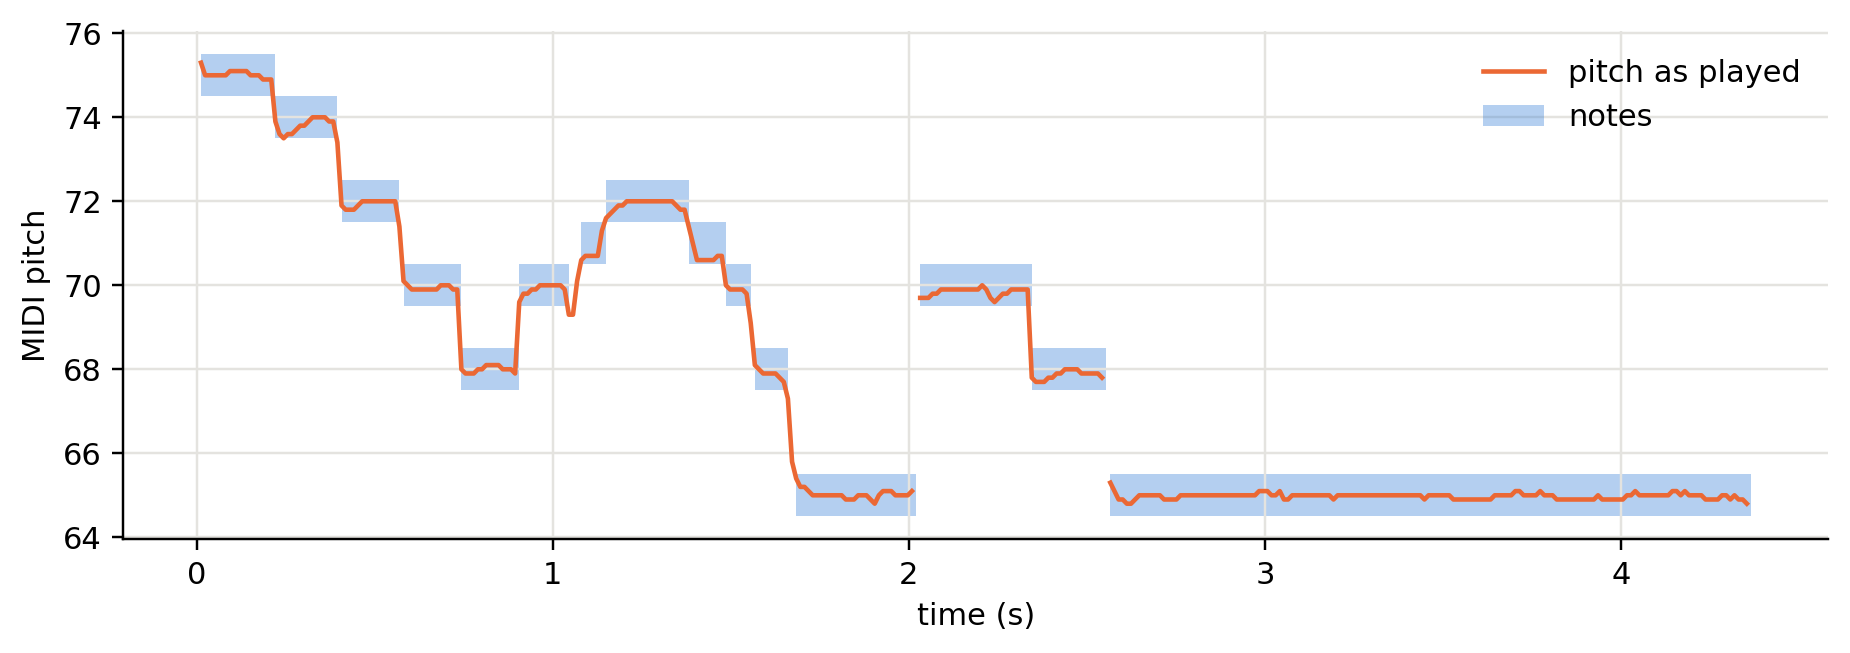

In [8]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(len(pitch)) * frame, pitch, color=ORANGE, lw=1.5, label="pitch as played")
for i, (s, d, p) in enumerate(tnotes): ax.add_patch(plt.Rectangle((s, p - 0.5), d, 1, color=BLUE, alpha=0.35, lw=0, label="notes" if i == 0 else None))
ax.set_xlabel("time (s)"); ax.set_ylabel("MIDI pitch"); ax.legend(frameon=False); plt.show()

In [9]:
organ = synth(tnotes, SR, decay=0.5); bell = synth(tnotes, SR, harmonics=(1, 0, 0.6, 0, 0.4, 0, 0.3), decay=6)
for name, w in (("the recording", y), ("its notes on an organ-like synth", organ), ("its notes on a bell-like synth", bell)):
    print(name); display(Audio(w, rate=SR))

the recording


[audio player: run the cell to listen]


its notes on an organ-like synth


[audio player: run the cell to listen]


its notes on a bell-like synth


[audio player: run the cell to listen]


What survived? Chroma (which of the 12 pitch classes sound) measures the notes; MFCCs measure the sound colour. Compare each resynthesis with the recording, frame by frame.

In [10]:
chroma = lambda w: librosa.feature.chroma_cqt(y=w, sr=SR, hop_length=512)
mfcc = lambda w: librosa.feature.mfcc(y=w, sr=SR, n_mfcc=13, hop_length=512)[1:]
on = librosa.feature.rms(y=y, hop_length=512)[0] > 0.02
def sim(a, b):
    n = min(a.shape[1], b.shape[1]); a, b = a[:, :n], b[:, :n]
    return float(np.mean((np.sum(a * b, 0) / (np.linalg.norm(a, axis=0) * np.linalg.norm(b, axis=0) + 1e-9))[on[:n]]))
rng = np.random.default_rng(0)
wrong = synth([(s, d, p + int(rng.integers(1, 11))) for s, d, p in tnotes], SR)
print(f"{'':28s} pitch content   sound colour")
for name, w in (("same notes, organ-like", organ), ("same notes, bell-like", bell), ("same rhythm, wrong notes", wrong)):
    print(f"{name:28s} {sim(chroma(y), chroma(w)):>10.2f} {sim(mfcc(y), mfcc(w)):>14.2f}")

                             pitch content   sound colour


same notes, organ-like             0.88           0.74
same notes, bell-like              0.94           0.56


same rhythm, wrong notes           0.18           0.62


A second opinion (optional, downloads CLAP, about 600 MB): which instrument does a text-audio model hear?

In [11]:
from transformers import ClapModel, ClapProcessor, logging
logging.set_verbosity_error(); torch.set_grad_enabled(False)
clap = ClapModel.from_pretrained("laion/clap-htsat-unfused").eval(); cproc = ClapProcessor.from_pretrained("laion/clap-htsat-unfused")
labels = ["trumpet", "organ", "bell", "piano", "violin"]
T = torch.nn.functional.normalize(clap.get_text_features(**cproc(text=[f"a solo {l}" for l in labels], return_tensors="pt", padding=True)), dim=-1)
for name, w in (("recording", y), ("organ-like", organ), ("bell-like", bell)):
    a = torch.nn.functional.normalize(clap.get_audio_features(**cproc(audios=[librosa.resample(w, orig_sr=SR, target_sr=48000)], sampling_rate=48000, return_tensors="pt")), dim=-1)
    cos = (a @ T.T)[0].numpy()
    print(f"{name:12s}", "  ".join(f"{l} {v:.2f}" for l, v in zip(labels, cos)), " -> ", labels[int(cos.argmax())])

recording    trumpet 0.60  organ 0.31  bell 0.07  piano 0.21  violin 0.36  ->  trumpet
organ-like   trumpet 0.29  organ 0.35  bell 0.17  piano 0.23  violin 0.14  ->  organ
bell-like    trumpet 0.16  organ 0.26  bell 0.27  piano 0.18  violin 0.14  ->  bell


## 4. Editing notes is arithmetic

Transposing up a whole tone is adding 2 to every pitch. Doubling the tempo is halving every time. Nothing is lost either way.

In [12]:
up = [(s, d, p + 2) for s, d, p in tnotes]
fast = [(s / 2, d / 2, p) for s, d, p in tnotes]
print("up a whole tone"); display(Audio(synth(up, SR, decay=0.5), rate=SR))
print("twice as fast"); display(Audio(synth(fast, SR, decay=0.5), rate=SR))

up a whole tone


[audio player: run the cell to listen]


twice as fast


[audio player: run the cell to listen]


## 5. A note model you can train here

Tokens: `BAR`, `POS_0..15` (sixteenth in the bar), `PITCH_p`, `DUR_d`. All chorales are moved to C major or A minor. First a bigram table (each token chosen from the one before), then a transformer with 850,000 parameters.

`STEPS = 1000` takes about five minutes on a CPU. The loss drops below the bigram table within the first 300 steps; the harmony takes longer to appear. The article's numbers use 2,000 steps (about 11 minutes on my laptop).

In [13]:
LO, HI = 30, 90
VOCAB = ["BAR"] + [f"POS_{i}" for i in range(16)] + [f"PITCH_{p}" for p in range(LO, HI)] + [f"DUR_{d}" for d in range(1, 17)]
ID = {t: i for i, t in enumerate(VOCAB)}; V = len(VOCAB); kind = lambda i: VOCAB[i].split("_")[0]

def encode(c):
    shift = (-c["tonic"] if c["mode"] == "major" else 9 - c["tonic"]) % 12
    if shift > 6: shift -= 12
    out, last_bar, last_pos = [], -1, None
    for s, d, p in sorted(c["notes"], key=lambda n: (n[0], -n[2])):
        bar, pos = divmod(s, 16)
        while last_bar < bar: out.append(ID["BAR"]); last_bar += 1; last_pos = None
        if pos != last_pos: out.append(ID[f"POS_{pos}"]); last_pos = pos
        out += [ID[f"PITCH_{min(HI - 1, max(LO, p + shift))}"], ID[f"DUR_{min(16, d)}"]]
    return out

def decode(ids):
    notes, bar, pos, pitch, bad, prev = [], -1, None, None, 0, None
    for i in ids:
        k, v = kind(i), VOCAB[i].split("_")[-1]
        legal = {"BAR": prev in (None, "BAR", "DUR"), "POS": prev in ("BAR", "DUR"), "PITCH": prev in ("POS", "DUR"), "DUR": prev == "PITCH"}[k]
        if k == "POS" and legal and prev == "DUR" and int(v) <= pos: legal = False
        if not legal: bad += 1; continue
        if k == "BAR": bar += 1; pos = None
        elif k == "POS": pos = int(v)
        elif k == "PITCH": pitch = int(v)
        else: notes.append((bar * 16 + pos, int(v), pitch))
        prev = k
    return notes, bad

rng = np.random.default_rng(0); order = rng.permutation(len(chorales)); n_val = len(chorales) // 10
val = [encode(chorales[i]) for i in order[:n_val]]; train = [encode(chorales[i]) for i in order[n_val:]]
print(" ".join(VOCAB[i] for i in train[0][:22]), "...")
print(f"{len(train)} training chorales, {sum(map(len, train)):,} tokens; vocabulary {V}")

BAR POS_0 PITCH_72 DUR_4 PITCH_67 DUR_4 PITCH_64 DUR_4 PITCH_60 DUR_4 POS_4 PITCH_72 DUR_8 PITCH_69 DUR_8 PITCH_64 DUR_8 PITCH_57 DUR_8 POS_12 PITCH_71 DUR_4 ...
334 training chorales, 193,344 tokens; vocabulary 93


In [14]:
bi = np.ones((V, V))
for s in train:
    for a, b in zip(s, s[1:]): bi[a, b] += 1
bi /= bi.sum(1, keepdims=True)
bi_loss = -np.mean(np.concatenate([np.log(bi[s[:-1], s[1:]]) for s in val]))
print(f"held-out loss, nats per token: uniform guess {np.log(V):.2f}, bigram {bi_loss:.2f} (as unsure as a fair choice among {np.exp(bi_loss):.1f} tokens)")

held-out loss, nats per token: uniform guess 4.53, bigram 2.28 (as unsure as a fair choice among 9.7 tokens)


In [15]:
STEPS, CTX, D = 1000, 256, 128
torch.manual_seed(0); torch.set_grad_enabled(True)
class Tiny(torch.nn.Module):
    def __init__(s):
        super().__init__()
        s.tok, s.pos = torch.nn.Embedding(V, D), torch.nn.Embedding(CTX, D)
        layer = torch.nn.TransformerEncoderLayer(D, 4, 4 * D, dropout=0.1, batch_first=True, norm_first=True)
        s.body, s.norm, s.head = torch.nn.TransformerEncoder(layer, 4), torch.nn.LayerNorm(D), torch.nn.Linear(D, V)
    def forward(s, x):
        T = x.shape[1]; mask = torch.triu(torch.full((T, T), float("-inf")), 1)
        return s.head(s.norm(s.body(s.tok(x) + s.pos(torch.arange(T)), mask=mask)))
model = Tiny(); print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=0.01); sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=STEPS)
def batch():
    xs = []
    for _ in range(32):
        s = train[rng.integers(len(train))]; i = rng.integers(0, max(1, len(s) - CTX - 1)); xs.append(s[i:i + CTX + 1])
    n = min(map(len, xs)); x = torch.tensor([q[:n] for q in xs]); return x[:, :-1], x[:, 1:]
def val_loss():
    model.eval(); tot = cnt = 0
    with torch.no_grad():
        for s in val:
            for i in range(0, len(s) - 1, CTX):
                x = torch.tensor(s[i:i + CTX + 1])[None]
                if x.shape[1] > 1: tot += torch.nn.functional.cross_entropy(model(x[:, :-1])[0], x[0, 1:], reduction="sum").item(); cnt += x.shape[1] - 1
    model.train(); return tot / cnt
t0 = time.time()
for step in range(1, STEPS + 1):
    x, yb = batch(); loss = torch.nn.functional.cross_entropy(model(x).reshape(-1, V), yb.reshape(-1))
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    if step % 250 == 0: print(f"step {step}: train {loss.item():.2f}, held-out {val_loss():.2f}, {time.time() - t0:.0f} s")
model.eval(); torch.set_grad_enabled(False)

850,013 parameters


step 250: train 2.11, held-out 2.03, 74 s


step 500: train 1.18, held-out 1.11, 148 s


step 750: train 1.00, held-out 0.95, 223 s


step 1000: train 0.97, held-out 0.92, 298 s


Generate from both, check them, and listen. "Triads" is the share of quarter-note beats on which the sounding notes form a major or minor triad.

In [16]:
def sample_model(n):
    x = torch.tensor([[ID["BAR"]]])
    for _ in range(n): x = torch.cat([x, torch.multinomial(torch.softmax(model(x[:, -CTX:])[0, -1], -1), 1)[None]], 1)
    return x[0].tolist()
def sample_bigram(n):
    s = [ID["BAR"]]
    for _ in range(n): s.append(int(rng.choice(V, p=bi[s[-1]])))
    return s
MAJOR = {0, 2, 4, 5, 7, 9, 11}
TRIADS = {frozenset((r + a) % 12 for a in iv) for r in range(12) for iv in ((0, 4, 7), (0, 3, 7))}
def checks(seqs):
    bad = tot = 0; scale, tri = [], []
    for s in seqs:
        notes, b = decode(s); bad += b; tot += len(s)
        if len(notes) < 8: continue
        pcs = np.bincount([p % 12 for _, _, p in notes], minlength=12)
        scale.append(max(sum(pcs[(k + r) % 12] for k in MAJOR) for r in range(12)) / pcs.sum())
        hits = beats = 0
        for t in range(0, max(a + d for a, d, _ in notes), 4):
            sounding = {p % 12 for a, d, p in notes if a <= t < a + d}
            if len(sounding) >= 3: beats += 1; hits += frozenset(sounding) in TRIADS
        if beats: tri.append(hits / beats)
    return 100 * (1 - bad / tot), 100 * np.mean(scale), 100 * np.mean(tri)
gen = [sample_model(400) for _ in range(5)]; big = [sample_bigram(400) for _ in range(5)]
print(f"{'':22s} grammar ok   in scale   triads on beats")
for name, seqs in (("real, held out", val), ("tiny transformer", gen), ("bigram table", big)):
    g, s, t = checks(seqs); print(f"{name:22s} {g:>9.1f}% {s:>9.1f}% {t:>12.1f}%")

                       grammar ok   in scale   triads on beats
real, held out             100.0%      93.1%         73.6%
tiny transformer            99.7%      93.7%         58.6%
bigram table                88.8%      92.7%          6.4%


In [17]:
for name, seq in (("real chorale", val[0][:400]), ("tiny transformer", gen[0]), ("bigram table", big[0])):
    notes, _ = decode(seq); notes = [n for n in notes if n[0] < 16 * 8]
    print(name); display(Audio(synth([(s * SIX, d * SIX, p) for s, d, p in notes], decay=0.8), rate=22050))

real chorale


[audio player: run the cell to listen]


tiny transformer


[audio player: run the cell to listen]


bigram table


[audio player: run the cell to listen]


The full scripts, including the tokenizer comparison with MidiTok and the text2midi against MusicGen comparison, are in this folder of the repository.